<a href="https://colab.research.google.com/github/reginamtxg/M-todos-num-ricos-I/blob/main/MNeville.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


#$\color{#F59E0B}{\Large \textbf{Metodo de Neville}}$
# algoritmo 3.1 | codigo  
*García Martínez Regina*

Para evaluar el polinomio de interpolación $P$ en los diferentes números $n+1, x_0,..., x_n$ en
el número $x$ para la función $f$:

*ENTRADA* números $x, x_0, x_1,...,x_n$; valores $f (x_0),f (x_1),...,f (x_n)$ como la primera
columna $Q_{0,0},Q_{1,0},... , Q_{n,0}$ de $Q$

*SALIDA* la tabla $Q$ con $P(x)= Q_{n,n}$

i = 0 (x_0 = 1.0): 0.7651977
i = 1 (x_1 = 1.3): 0.6200860   0.5233449
i = 2 (x_2 = 1.6): 0.4554022   0.5102968   0.5124715
i = 3 (x_3 = 1.9): 0.2818186   0.5132634   0.5112857   0.5118127
i = 4 (x_4 = 2.2): 0.1103623   0.5104270   0.5137361   0.5118302   0.5118200
Q_{n,n}= 1.5: 0.5118200


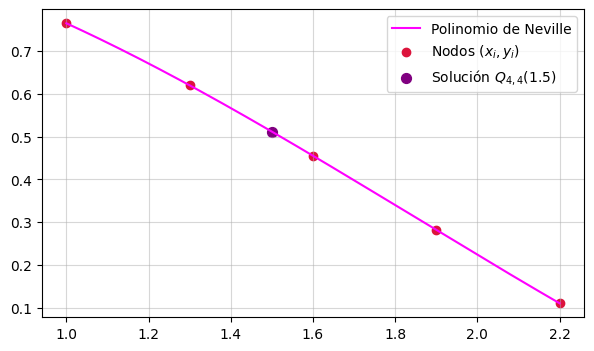

In [13]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

def algoritmo_neville(x_eval, x_nodos, y_nodos):
    #n=numero de nodos
    n = len(x_nodos) - 1
    x = sp.Float(x_eval)
    #los convertimos a flotantes
    xs = [sp.Float(val) for val in x_nodos]
    # le damos la forma a la tabla para que quede tipo escalonada
    Q = [[sp.Float(0) for _ in range(n + 1)] for _ in range(n + 1)]
    for i in range(n + 1):
        Q[i][0] = sp.Float(y_nodos[i])

    for i in range(1, n + 1):#aplicando el paso 1 del algoritmo
        for j in range(1, i + 1):#paso 2
            Q[i][j] = ((x - xs[i - j]) * Q[i][j - 1] - (x - xs[i]) * Q[i - 1][j - 1]) / (xs[i] - xs[i - j])

    #tabla
    return Q, Q[n][n]

#aplicacion del ejemplo
x_datos = [1.0, 1.3, 1.6, 1.9, 2.2]
y_datos = [0.7651977, 0.6200860, 0.4554022, 0.2818186, 0.1103623]
x_punto = 1.5

tabla_Q, aproximacion_final = algoritmo_neville(x_punto, x_datos, y_datos)#calculamos la aproximacion final

for i in range(len(x_datos)):#para imprimir la tabla
    fila = [f"{float(tabla_Q[i][j]):.7f}" for j in range(i + 1)]
    print(f"i = {i} (x_{i} = {x_datos[i]}): " + "   ".join(fila))

print(f"Q_{{n,n}}= {x_punto}: {float(aproximacion_final):.7f}")#.7f es para ocupar 7 decimales

#grafica
x_graf = np.linspace(min(x_datos), max(x_datos), 150)
y_graf = [float(algoritmo_neville(val, x_datos, y_datos)[1]) for val in x_graf]

plt.figure(figsize=(7, 4))
plt.plot(x_graf, y_graf, color="magenta", label="Polinomio de Neville")
plt.scatter(x_datos, y_datos, color="crimson", label="Nodos $(x_i, y_i)$")
plt.scatter([x_punto], [float(aproximacion_final)], color="purple", s=50, label=f"Solución $Q_{{4,4}}({x_punto})$")
plt.legend()
plt.grid(True, linestyle="-", alpha=0.5)
plt.show()